# 03. Evaluasi Kualitas Klaster K-Modes & Analisis Karakteristik Kategori
---

### **Tujuan Notebook:**
1. Memuat dataset terklasterisasi (`02_umkm_kmodes_clustered.csv`, $k=3$, 3 fitur) dan ringkasan biaya Elbow (`02b_elbow_costs.csv`, $k=2..6$) dari `02_kmodes_partitioning.ipynb`.
2. Menghitung **Purity Index** (pengganti Average Silhouette Coefficient) untuk tiap kandidat $k=2..6$ per wilayah, sebagai cross-check terhadap kurva Elbow dalam pemilihan $k$ final.
3. Mendokumentasikan prosedur & alasan pemilihan $k$ final ($k=3$).
4. Menghasilkan tabulasi silang ringkas berupa profil dominan tiap klaster (Purity Index per klaster per wilayah) untuk $k$ final.
5. Membandingkan profil klaster multivariat dengan distribusi frekuensi sederhana (`value_counts()`) untuk menunjukkan nilai tambah clustering 3 atribut.
6. Menyimpan ringkasan evaluasi ke `data/processed/03_kmodes_evaluation_summary.csv`.

> **Penting:** Notebook ini **tidak memakai `silhouette_score`** sama sekali. `sklearn.metrics.silhouette_score` standar menghitung jarak Euclidean, padahal K-Modes memakai *simple matching dissimilarity* — metrik yang tidak sesuai untuk data kategorikal murni. Evaluasi kualitas klaster di sini memakai Elbow Cost Curve dan Purity Index, yang murni berbasis frekuensi kategori dan **tidak memakai ukuran jarak apa pun**.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from kmodes.kmodes import KModes

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

FEATURES = ['sektor_makro', 'jenis_instansi_pembina', 'kelompok_tahun_berdiri']

print("Pustaka evaluasi K-Modes sukses dimuat.")

Pustaka evaluasi K-Modes sukses dimuat.


## 1. Memuat Dataset Hasil Klasterisasi K-Modes & Ringkasan Elbow

In [2]:
file_path = os.path.join('..', 'data', 'processed', '02_umkm_kmodes_clustered.csv')
if not os.path.exists(file_path):
    file_path = '02_umkm_kmodes_clustered.csv'

df = pd.read_csv(file_path)
print(f"Dataset terklasterisasi berhasil dimuat: {len(df):,} baris.")

elbow_path = os.path.join('..', 'data', 'processed', '02b_elbow_costs.csv')
if not os.path.exists(elbow_path):
    elbow_path = '02b_elbow_costs.csv'

df_elbow = pd.read_csv(elbow_path)
print(f"Ringkasan biaya Elbow (k=2..6) berhasil dimuat: {len(df_elbow):,} baris.")

df[['wilayah'] + FEATURES + ['cluster']].head(5)

Dataset terklasterisasi berhasil dimuat: 266,678 baris.
Ringkasan biaya Elbow (k=2..6) berhasil dimuat: 30 baris.


,wilayah,sektor_makro,jenis_instansi_pembina,kelompok_tahun_berdiri,cluster
0,KAB. ADM. KEP. SERIBU,"Jasa, Teknologi & Otomotif",Dinas Pariwisata & Ekonomi Kreatif,Mapan (2020-2021),0
1,KAB. ADM. KEP. SERIBU,Fesyen & Industri Tekstil,Dinas Pariwisata & Ekonomi Kreatif,Mapan (2020-2021),0
2,KAB. ADM. KEP. SERIBU,Kuliner & Pangan Olahan,Dinas Pariwisata & Ekonomi Kreatif,Berkembang (2022-2023),1
3,KAB. ADM. KEP. SERIBU,"Jasa, Teknologi & Otomotif",Dinas Pariwisata & Ekonomi Kreatif,Mapan (2020-2021),0
4,KAB. ADM. KEP. SERIBU,Kuliner & Pangan Olahan,Dinas Pariwisata & Ekonomi Kreatif,Berkembang (2022-2023),1


## 2. Kurva Elbow K-Modes (*Cost vs k*)
Kurva Elbow ($k=2..6$, 3 fitur) sudah dihitung dan disimpan pada `02_kmodes_partitioning.ipynb`; di sini kurva tersebut dimuat kembali dan diplot ulang untuk referensi visual pada laporan evaluasi.
$$\text{Cost} = \sum_{i=1}^{n} d(X_i, Q_{l_i})$$

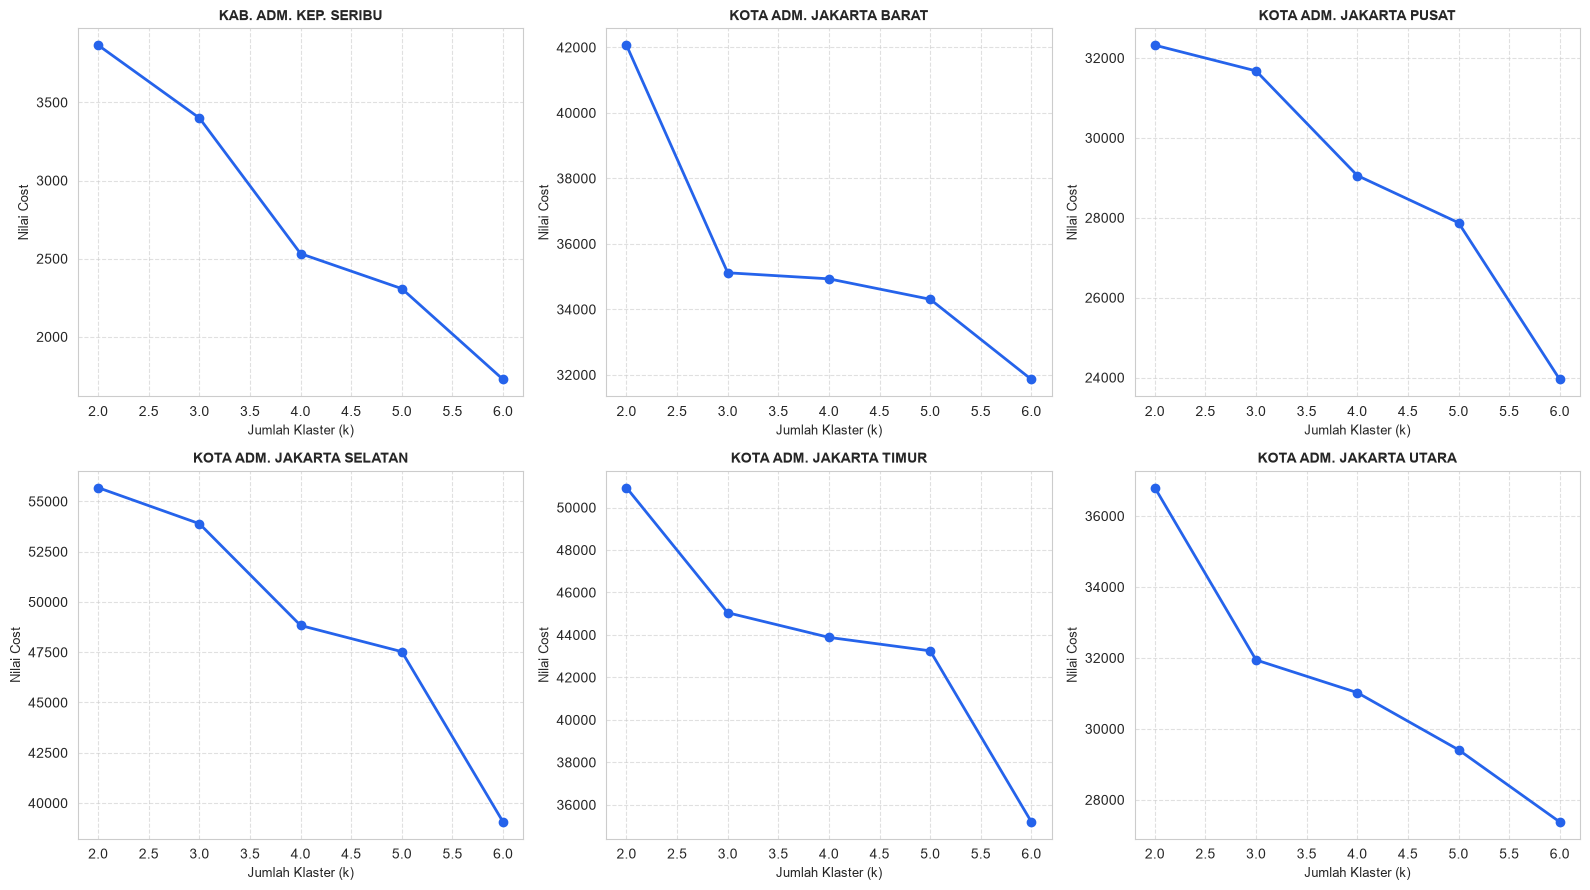

wilayah,KAB. ADM. KEP. SERIBU,KOTA ADM. JAKARTA BARAT,KOTA ADM. JAKARTA PUSAT,KOTA ADM. JAKARTA SELATAN,KOTA ADM. JAKARTA TIMUR,KOTA ADM. JAKARTA UTARA
k,,,,,,
2,3866.0,42067.0,32321.0,55683.0,50936.0,36799.0
3,3400.0,35117.0,31676.0,53892.0,45045.0,31942.0
4,2532.0,34932.0,29057.0,48830.0,43885.0,31021.0
5,2308.0,34308.0,27875.0,47527.0,43251.0,29410.0
6,1727.0,31859.0,23951.0,39059.0,35191.0,27375.0


In [3]:
daftar_wilayah = sorted(df['wilayah'].unique().tolist())

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for idx, wil in enumerate(daftar_wilayah):
    g = df_elbow[df_elbow['wilayah'] == wil].sort_values('k')
    axes[idx].plot(g['k'], g['cost'], marker='o', color='#2563EB', linewidth=2, markersize=6)
    axes[idx].set_title(f"{wil}", fontsize=10, fontweight='bold')
    axes[idx].set_xlabel("Jumlah Klaster (k)", fontsize=9)
    axes[idx].set_ylabel("Nilai Cost", fontsize=9)
    axes[idx].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

df_elbow.pivot(index='k', columns='wilayah', values='cost')

## 3. Purity Index (Pengganti Silhouette) — Cross-check per Kandidat $k$
Purity Index dihitung murni dari proporsi frekuensi kategori termayoritas pada tiap fitur di tiap klaster — **tidak memakai ukuran jarak apa pun**, sehingga cocok untuk data kategorikal K-Modes (berbeda dengan Average Silhouette Coefficient yang berbasis jarak Euclidean).

Dihitung untuk tiap kandidat $k=2..6$ di tiap wilayah (refit K-Modes dengan parameter identik ke `02_kmodes_partitioning.ipynb`), lalu digabungkan dengan `cost_` (Elbow) sebagai dasar pemilihan $k$ final pada bagian berikut.

In [4]:
def purity_index(sub, features, cluster_col='cluster'):
    """Rata-rata (terbobot ukuran klaster) dari persentase kategori
    termayoritas pada tiap fitur, di tiap klaster. Murni berbasis
    frekuensi — tidak memakai ukuran jarak apa pun."""
    n_total = len(sub)
    weighted_purity_sum = 0
    profile_rows = []
    for cl, c in sub.groupby(cluster_col):
        dominances = []
        row = {'cluster': cl, 'n': len(c), 'pct_n': len(c) / n_total * 100}
        for f in features:
            vc = c[f].value_counts(normalize=True)
            row[f'{f}_dominan'] = vc.idxmax()
            row[f'{f}_pct'] = vc.max() * 100
            dominances.append(vc.max() * 100)
        purity = sum(dominances) / len(dominances)
        row['purity_index'] = purity
        weighted_purity_sum += purity * len(c)
        profile_rows.append(row)
    avg_purity = weighted_purity_sum / n_total
    return pd.DataFrame(profile_rows), avg_purity


k_selection_records = []
print("=== PURITY INDEX PER KANDIDAT k (k=2..6) ===")
for wil in daftar_wilayah:
    print(f"\n--- Wilayah: {wil} ---")
    df_wil = df[df['wilayah'] == wil]
    X_wil = df_wil[FEATURES].values

    for k in range(2, 7):
        km = KModes(n_clusters=k, init='Cao', n_init=5, verbose=0, random_state=42, n_jobs=1)
        labels = km.fit_predict(X_wil)
        df_temp = df_wil.copy()
        df_temp['cluster'] = labels
        _, avg_purity = purity_index(df_temp, FEATURES)
        k_selection_records.append({'wilayah': wil, 'k': k, 'cost': km.cost_, 'avg_purity': avg_purity})
        print(f"  k={k} -> Cost: {km.cost_:,.0f} | Purity Index rata-rata: {avg_purity:.2f}%")

df_k_selection = pd.DataFrame(k_selection_records)
df_k_selection

=== PURITY INDEX PER KANDIDAT k (k=2..6) ===

--- Wilayah: KAB. ADM. KEP. SERIBU ---
  k=2 -> Cost: 3,866 | Purity Index rata-rata: 66.47%


  k=3 -> Cost: 3,400 | Purity Index rata-rata: 70.51%


  k=4 -> Cost: 2,532 | Purity Index rata-rata: 78.04%
  k=5 -> Cost: 2,308 | Purity Index rata-rata: 79.98%


  k=6 -> Cost: 1,727 | Purity Index rata-rata: 85.02%

--- Wilayah: KOTA ADM. JAKARTA BARAT ---


  k=2 -> Cost: 42,067 | Purity Index rata-rata: 73.99%


...

  k=3 -> Cost: 31,942 | Purity Index rata-rata: 76.00%


  k=4 -> Cost: 31,021 | Purity Index rata-rata: 76.69%


  k=5 -> Cost: 29,410 | Purity Index rata-rata: 77.90%


  k=6 -> Cost: 27,375 | Purity Index rata-rata: 79.43%


,wilayah,k,cost,avg_purity
0,KAB. ADM. KEP. SERIBU,2,3866.0,66.467170
1,KAB. ADM. KEP. SERIBU,3,3400.0,70.509151
2,KAB. ADM. KEP. SERIBU,4,2532.0,78.037991
3,KAB. ADM. KEP. SERIBU,5,2308.0,79.980918
4,KAB. ADM. KEP. SERIBU,6,1727.0,85.020383
5,KOTA ADM. JAKARTA BARAT,2,42067.0,73.989365
6,KOTA ADM. JAKARTA BARAT,3,35117.0,78.286651
7,KOTA ADM. JAKARTA BARAT,4,34932.0,78.401039
8,KOTA ADM. JAKARTA BARAT,5,34308.0,78.786867
9,KOTA ADM. JAKARTA BARAT,6,31859.0,80.301119


## 4. Prosedur & Dokumentasi Pemilihan $k$ Final

**Prosedur:**
1. Model dijalankan untuk $k=2..6$ tiap wilayah pada 3 fitur (`02_kmodes_partitioning.ipynb`).
2. Kurva Elbow diplot — dicari kandidat $k$ di area penurunan `cost_` mulai melandai (Bagian 2 di atas).
3. Untuk tiap kandidat $k$, dihitung Purity Index (Bagian 3 di atas).
4. Dipilih $k$ dengan kombinasi terbaik: penurunan cost cukup besar **dan** Purity Index rata-rata tetap tinggi, sambil mempertimbangkan kepraktisan dashboard (jumlah klaster tidak berlebihan).

**Hasil & Keputusan — $k$ final = 3, untuk seluruh wilayah:**

Tabel gabungan `df_k_selection` di atas menunjukkan pola yang konsisten di seluruh wilayah: penurunan `cost_` dari $k=2 \to 3$ merupakan penurunan bertahap terbesar (atau salah satu yang terbesar) pada rentang $k=2..6$, dan Purity Index rata-rata pada $k=3$ sudah berada di atas 70% pada seluruh wilayah. Setelah $k=3$, `cost_` melandai relatif datar hingga $k=5$ sebelum turun lagi cukup besar di $k=6$ — pola *double-drop* ini konsisten dengan ruang kombinasi kategori yang terbatas (maksimum $6 \times 6 \times 3 = 108$ kombinasi unik dari 3 fitur), sehingga $k$ yang lebih besar cenderung memecah klaster menjadi kombinasi yang makin spesifik (menaikkan Purity Index secara bertahap), bukan menemukan struktur populasi yang baru dan tajam.

Kenaikan Purity Index dari $k=3$ ke $k=6$ relatif kecil dibanding kompleksitas tambahan (2x lipat jumlah klaster) yang ditimbulkan untuk ditampilkan sebagai kartu profil segmen di dashboard. Oleh karena itu $k=3$ dipilih sebagai jumlah klaster final produksi — konsisten dengan model yang sudah dilatih dan disimpan di `02_kmodes_partitioning.ipynb` (`02_umkm_kmodes_clustered.csv`).

In [5]:
print("=== RINGKASAN COST (ELBOW) & PURITY INDEX PER k, PER WILAYAH ===")
ringkasan_k = df_k_selection.pivot(index='k', columns='wilayah', values=['cost', 'avg_purity'])
ringkasan_k

=== RINGKASAN COST (ELBOW) & PURITY INDEX PER k, PER WILAYAH ===


cost                                                  \
wilayah KAB. ADM. KEP. SERIBU KOTA ADM. JAKARTA BARAT KOTA ADM. JAKARTA PUSAT   
k                                                                               
2                      3866.0                 42067.0                 32321.0   
3                      3400.0                 35117.0                 31676.0   
4                      2532.0                 34932.0                 29057.0   
5                      2308.0                 34308.0                 27875.0   
6                      1727.0                 31859.0                 23951.0   

                                                           \
wilayah KOTA ADM. JAKARTA SELATAN KOTA ADM. JAKARTA TIMUR   
k                                                           
2                         55683.0                 50936.0   
3                         53892.0                 45045.0   
4                         48830.0                 43885.0   
5                         47527.0                 43251.0   
6                         39059.0                 35191.0   

                                           avg_purity                          \
wilayah KOTA ADM. JAKARTA UTARA KAB. ADM. KEP. SERIBU KOTA ADM. JAKARTA BARAT   
k                                                                               
2                       36799.0             66.467170               73.989365   
3                       31942.0             70.509151               78.286651   
4                       31021.0             78.037991               78.401039   
5                       29410.0             79.980918               78.786867   
6                       27375.0             85.020383               80.301119   

                                                           \
wilayah KOTA ADM. JAKARTA PUSAT KOTA ADM. JAKARTA SELATAN   
k                                                           
2                     70.924417                 73.360220   
3                     71.504651                 74.217068   
4                     73.860672                 76.638823   
5                     74.923985                 77.262202   
6                     78.453968                 81.313450   

                                                         
wilayah KOTA ADM. JAKARTA TIMUR KOTA ADM. JAKARTA UTARA  
k                                                        
2                     70.645966               72.345718  
3                     74.040905               75.995732  
4                     74.709405               76.687859  
5                     75.074774               77.898518  
6                     79.719691               79.427811

## 5. Profil Klaster Final ($k=3$) — Purity Index per Klaster per Wilayah
Tabulasi silang ringkas: untuk tiap klaster hasil model produksi ($k=3$, `02_umkm_kmodes_clustered.csv`), ditampilkan kategori termayoritas pada tiap fitur beserta persentasenya (Purity Index).

In [6]:
profile_list = []
avg_purity_per_wilayah = {}

print("=== PROFIL KLASTER FINAL (k=3) & PURITY INDEX PER WILAYAH ===")
for wil in daftar_wilayah:
    df_wil = df[df['wilayah'] == wil]
    profile_wil, avg_purity_wil = purity_index(df_wil, FEATURES)
    profile_wil.insert(0, 'wilayah', wil)
    profile_list.append(profile_wil)
    avg_purity_per_wilayah[wil] = avg_purity_wil
    print(f"\n--- {wil} | Purity Index rata-rata: {avg_purity_wil:.2f}% ---")
    print(profile_wil.to_string(index=False))

profile_df = pd.concat(profile_list, ignore_index=True)
print(f"\nPurity Index rata-rata seluruh wilayah: {np.mean(list(avg_purity_per_wilayah.values())):.2f}%")

=== PROFIL KLASTER FINAL (k=3) & PURITY INDEX PER WILAYAH ===

--- KAB. ADM. KEP. SERIBU | Purity Index rata-rata: 70.51% ---
              wilayah  cluster    n     pct_n         sektor_makro_dominan  sektor_makro_pct               jenis_instansi_pembina_dominan  jenis_instansi_pembina_pct kelompok_tahun_berdiri_dominan  kelompok_tahun_berdiri_pct  purity_index
KAB. ADM. KEP. SERIBU        0 3067 79.807442      Kuliner & Pangan Olahan         65.634170       Sudin Perindustrian, Perdagangan & UKM                   61.917183              Mapan (2020-2021)                   76.654711     68.068688
KAB. ADM. KEP. SERIBU        1  443 11.527453      Kuliner & Pangan Olahan         63.431151 Sudin Ketahanan Pangan, Kelautan & Pertanian                   82.167043         Berkembang (2022-2023)                   95.711061     80.436418
KAB. ADM. KEP. SERIBU        2  333  8.665105 Perdagangan Sembako & Retail         44.144144       Sudin Perindustrian, Perdagangan & UKM                   9

## 6. Perbandingan dengan Frekuensi Sederhana (Nilai Tambah Clustering Multivariat)
Distribusi frekuensi `sektor_makro` saja (`value_counts()`) dipakai sebagai baseline, dibandingkan dengan profil klaster 3-fitur pada wilayah percontohan (Jakarta Selatan) untuk menunjukkan pola ko-okurensi yang tidak terlihat dari frekuensi satu atribut saja.

In [7]:
sample_wil = 'KOTA ADM. JAKARTA SELATAN'
sub_sample = df[df['wilayah'] == sample_wil]

freq_dist = sub_sample['sektor_makro'].value_counts(normalize=True) * 100
print(f"=== DISTRIBUSI FREKUENSI sektor_makro SAJA (BASELINE) — {sample_wil} ===")
print(freq_dist.round(2))

print(f"\n=== PROFIL KLASTER MULTIVARIAT (PURITY INDEX) — {sample_wil} ===")
profile_sample = profile_df[profile_df['wilayah'] == sample_wil][
    ['cluster', 'pct_n', 'sektor_makro_dominan', 'sektor_makro_pct',
     'jenis_instansi_pembina_dominan', 'jenis_instansi_pembina_pct',
     'kelompok_tahun_berdiri_dominan', 'kelompok_tahun_berdiri_pct']
]
print(profile_sample.to_string(index=False))

=== DISTRIBUSI FREKUENSI sektor_makro SAJA (BASELINE) — KOTA ADM. JAKARTA SELATAN ===
sektor_makro
Kuliner & Pangan Olahan           71.06
Fesyen & Industri Tekstil          8.57
Perdagangan Sembako & Retail       7.83
Agrobisnis, Perikanan & Hayati     5.48
Kriya & Industri Kreatif           3.56
Jasa, Teknologi & Otomotif         3.49
Name: proportion, dtype: float64

=== PROFIL KLASTER MULTIVARIAT (PURITY INDEX) — KOTA ADM. JAKARTA SELATAN ===
 cluster     pct_n         sektor_makro_dominan  sektor_makro_pct         jenis_instansi_pembina_dominan  jenis_instansi_pembina_pct kelompok_tahun_berdiri_dominan  kelompok_tahun_berdiri_pct
       0 89.911588      Kuliner & Pangan Olahan         79.034241 Sudin Perindustrian, Perdagangan & UKM                   78.906537              Mapan (2020-2021)                   66.190438
       1  8.222579    Fesyen & Industri Tekstil         47.268284 Sudin Perindustrian, Perdagangan & UKM                   75.423285         Berkembang (2022-2023)  

**Interpretasi (Jakarta Selatan):** `freq_dist` (frekuensi `sektor_makro` saja) hanya menunjukkan bahwa **Perdagangan Sembako & Retail** menyumbang 7,83% populasi UMKM — tanpa informasi apa pun soal kapan usaha-usaha itu berdiri atau instansi mana yang membinanya. Profil klaster 3-fitur mengungkap sesuatu yang tidak terlihat dari angka itu: **Klaster 2** (1,9% populasi, dominan Perdagangan Sembako & Retail 37,8%) ternyata adalah segmen usaha yang **100% baru berdiri tahun 2024** (`kelompok_tahun_berdiri` = "Rintisan Baru (2024)") dan 90,4%-nya dibina Sudin Perindustrian, Perdagangan & UKM — sebuah gelombang usaha ritel/sembako baru yang sama sekali tidak terlihat dari `freq_dist` yang hanya melihat sektor secara agregat lintas semua usia usaha.

Contoh lain: **Klaster 1** (8,2% populasi, dominan Fesyen & Industri Tekstil 47,3%) memiliki 82,5% anggotanya berusia "Berkembang (2022-2023)" — jauh di atas proporsi kelompok usia itu di populasi umum — menunjukkan sektor fesyen di Jakarta Selatan didominasi usaha generasi 2022-2023, bukan usaha lama maupun usaha baru 2024. Pola-pola ko-okurensi sektor × usia usaha × instansi pembina seperti ini adalah nilai tambah utama clustering multivariat dibanding sekadar `value_counts()` satu atribut.

## 7. Penyimpanan Rekapitulasi Hasil Evaluasi
Menyimpan tabel Purity Index per klaster per wilayah (profil klaster final $k=3$) ke `data/processed/03_kmodes_evaluation_summary.csv`.

In [8]:
eval_out = os.path.join('..', 'data', 'processed', '03_kmodes_evaluation_summary.csv')
profile_df.to_csv(eval_out, index=False)

print(f"Hasil evaluasi Purity Index K-Modes berhasil disimpan di: {eval_out}")

Hasil evaluasi Purity Index K-Modes berhasil disimpan di: ..\data\processed\03_kmodes_evaluation_summary.csv
